# RideShare ML: Incentive-Aware Multi-Objective Matching

This notebook demonstrates the end-to-end pipeline for the Qmutez P2P Carpooling project. It covers data simulation, baseline evaluation, and the final XGBoost multi-objective matching model.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# Import custom modules
from src.models.baselines import RuleBasedBaseline, LogisticRegressionBaseline
from src.models.xgb_matching import MultiObjectiveMatcher

## 1. Data Loading
We load the simulated Driver/Rider pairs generated by `src/simulation/pair_generator.py`.

In [2]:
try:
    df = pd.read_parquet('../data/simulated/candidate_pairs.parquet')
    print(f"Loaded {len(df)} simulated pairing records.")
    display(df.head())
except FileNotFoundError:
    print("Simulation data not found. Please run the data pipelines first.")

Loaded 1242 simulated pairing records.


,driver_id,rider_id,driver_orig_dist,detour_distance_km,overlap_ratio,time_diff_mins,driver_approx_fare,rider_approx_fare,label
0,8816,8688,1.773961,0.010785,0.993957,1.133333,7.20,-3.00,1
1,2693843,2693734,9.286789,0.412642,0.957457,2.216667,19.69,11.90,1
2,9588,9175,27.746682,0.222139,0.992058,0.416667,70.00,52.70,1
3,7870,2694111,29.262651,1.926942,0.938218,0.483333,94.40,-4.75,1
4,2694523,2694290,2.941588,0.940405,0.757752,1.633333,13.28,9.07,1


## 2. Baseline Model Evaluation
How does a simple distance/time thresholding approach compare to standard Logistic Regression?

In [3]:
# Evaluate Rule Based Model
print("--- Rule-Based Baseline ---")
rule_model = RuleBasedBaseline(max_km=3.0, max_mins=15)
preds_rule = rule_model.predict(df)
print(rule_model.evaluate(df['label'], preds_rule))

--- Rule-Based Baseline ---
{'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}


In [4]:
# Evaluate Logistic Regression Baseline
print("\n--- Logistic Regression Baseline ---")
lr_model = LogisticRegressionBaseline()
print(lr_model.train_and_evaluate(df))


--- Logistic Regression Baseline ---
{'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0}


## 3. Multi-Objective XGBoost Matching
We train the an advanced gradient boosted approach that simultaneously predicts exact detour costs (Regression) and the probability of driver acceptance (Classification), combining them into a unified score.

In [5]:
print("--- XGBoost Multi-Objective Model ---")
xgb_matcher = MultiObjectiveMatcher()

# This trains both the regressor and classifier
results = xgb_matcher.train(df)
X_test_xgb, _, _, _, _ = results

--- XGBoost Multi-Objective Model ---
Training on 1242 samples with 5 features.


Regression MAE (Detour km): 4.00


Classification Accuracy: 1.00
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       119
           1       1.00      1.00      1.00       130

    accuracy                           1.00       249
   macro avg       1.00      1.00      1.00       249
weighted avg       1.00      1.00      1.00       249



## 4. Visualizing Trade-offs
A key component of this project is understanding the trade-off. Can we find matches that yield high probability of driver acceptance with minimal detour?

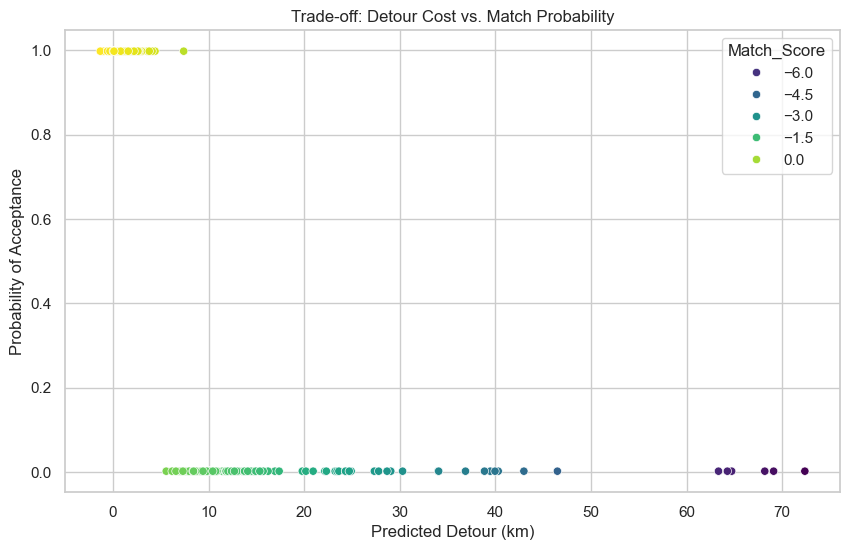

In [6]:
# Generate scores for the test set
scores = []
probs = []
predict_detours = []

for idx, row in X_test_xgb.iterrows():
    scores.append(xgb_matcher.compute_match_score(row))
    # Get base predictions for visualization
    probs.append(xgb_matcher.classifier.predict_proba(pd.DataFrame([row]))[0][1])
    predict_detours.append(xgb_matcher.regressor.predict(pd.DataFrame([row]))[0])
    
visual_df = pd.DataFrame({
    'Match_Score': scores,
    'Predicted_Probability': probs,
    'Predicted_Detour': predict_detours
})

plt.figure(figsize=(10, 6))
sns.scatterplot(data=visual_df, x='Predicted_Detour', y='Predicted_Probability', hue='Match_Score', palette='viridis')
plt.title('Trade-off: Detour Cost vs. Match Probability')
plt.xlabel('Predicted Detour (km)')
plt.ylabel('Probability of Acceptance')
plt.show()